# 04 · Simulation

Backtests of the stock-picking rules. **Part 1 (this version): the baseline rule grid.** The model
rules join later, through the same `pred*` columns and the same simulation.

**The rule:** at each month-end, buy the top 1, 5 or 10 members by their past return (over 1, 3, 6 or
12 months, or 12 months skipping the latest), equal weight, at the next open, and hold for 1, 3, 6 or
12 months. That's 5 × 3 × 4 = **60 rules**, and every one is reported.

**How it's simulated:**
- **Staggered portfolios.** With an X-month hold, 1/X of the money is reinvested each month, so the
  result doesn't depend on the starting month.
- **Costs.** 10 bps (0.1%) are charged on every buy and every sell. A stock kept from one month's
  picks to the next is only traded by the weight difference.
- **Delistings.** A delisted stock is valued at its last price and then held as cash.
- **Benchmarks.** SPY, and an equal-weight basket of every member rebalanced monthly. Both are
  gross: SPY's fee is in its price, and the basket is a yardstick, not a strategy.

The rule fits nothing, so it runs over the **whole period (Feb 2010 to Oct 2026)** with no train/test
split. But picking the best of 60 is itself a choice, so Section 4 chooses the best rule on the
development years (2010–2022) only and follows it through the **test years (2023 on)**, the same
untouched window the models are scored on.

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.
> The early years still miss most acquired companies (survivorship bias flatters the rule).

In [1]:
import pandas as pd

from sp500_momentum import backtest as bt
from sp500_momentum import config, nb, plots

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

## 1. The rule columns

Each rule is a 0/1 column on the monthly table (`pred_mom_<look-back>_top<N>`): 1 means "buy this member
at the next open". For example, the five picks of the 6-month rule at the latest month-end:

In [2]:
panel = bt.add_rule_preds(pd.read_parquet(config.MONTHLY_PANEL))
preds = [c for c in panel if c.startswith("pred_mom_")]
last = panel["date"].max()
print(
    f"{len(preds)} rule columns; picks per month-end: "
    f"{panel.groupby('date')[preds].sum().iloc[:-1].mean().round(1).unique().tolist()}"
)
panel.loc[(panel["date"] == last) & (panel["pred_mom_6m_top5"] == 1), ["date", "ticker", "ret_6m"]]

15 rule columns; picks per month-end: [1.0, 5.0, 10.0]


,date,ticker,ret_6m
101041,2026-10-30,CRL,1.1525
101043,2026-10-30,CRWD,1.2473
101059,2026-10-30,DELL,1.0368
101242,2026-10-30,MRNA,3.8263
101282,2026-10-30,PANW,1.0403


## 2. Benchmarks

In [3]:
values = bt.value_matrix(pd.read_parquet(config.MONTHLY_PRICES))
bench = bt.benchmark_returns(panel, values)
rf = bt.risk_free(pd.read_csv(config.FRED_DIR / "FEDFUNDS.csv"))
print(f"Months earned: {len(bench)} ({bench.index.min()} to {bench.index.max()})")
cols = ["cagr", "volatility", "sharpe", "max_drawdown", "beats_spy_months"]
bt.benchmark_table(bench, rf)[cols]

Months earned: 201 (2010-02 to 2026-10)


,cagr,volatility,sharpe,max_drawdown,beats_spy_months
spy,0.1434,0.1481,0.8804,-0.2331,NaN
equal_weight,0.1379,0.1607,0.7940,-0.3013,0.5124


The equal-weight basket earns about the same as SPY, with more volatility and a deeper fall. Sharpe
ratios here subtract the Fed Funds rate as the risk-free return.

## 3. The full grid (about a minute to run)

In [4]:
rets, costs = bt.run_grid(panel, values, config.HOLD_MONTHS)
grid = bt.grid_table(rets, bench, rf, costs)
grid.to_csv(config.REPORTS_DIR / "baseline_grid_2010_2026.csv")  # all 60 rules + benchmarks
print(f"{rets.shape[1]} rules simulated; the full table is in reports/baseline_grid_2010_2026.csv")
show = [
    "lookback",
    "top_n",
    "hold",
    "cagr",
    "volatility",
    "sharpe",
    "max_drawdown",
    "t_vs_spy",
    "cost_per_year",
]
grid[show].head(10)

60 rules simulated; the full table is in reports/baseline_grid_2010_2026.csv


,lookback,top_n,hold,cagr,volatility,sharpe,max_drawdown,t_vs_spy,cost_per_year
cell,,,,,,,,,
pred_mom_6m_top5_h6,ret_6m,5,6,0.2816,0.2875,0.9562,-0.2733,2.7667,0.0037
pred_mom_6m_top5_h3,ret_6m,5,3,0.2798,0.2884,0.9476,-0.2493,2.6357,0.0061
pred_mom_6m_top5_h12,ret_6m,5,12,0.2460,0.2557,0.9335,-0.2717,2.5637,0.0020
pred_mom_3m_top10_h12,ret_3m,10,12,0.2024,0.2164,0.8951,-0.2731,2.0513,0.0019
pred_mom_3m_top10_h6,ret_3m,10,6,0.2092,0.2280,0.8850,-0.3025,1.9842,0.0037
pred_mom_6m_top10_h12,ret_6m,10,12,0.2122,0.2336,0.8807,-0.2540,2.1144,0.0020
spy,NaN,<NA>,<NA>,0.1434,0.1481,0.8804,-0.2331,NaN,NaN
pred_mom_3m_top10_h3,ret_3m,10,3,0.2018,0.2208,0.8782,-0.2862,1.7140,0.0073
pred_mom_1m_top10_h12,ret_1m,10,12,0.1884,0.2047,0.8761,-0.3144,2.0114,0.0020


The ten best rules by Sharpe ratio. `t_vs_spy` is the t-statistic of the average monthly return
over SPY's. About 2 would be convincing for one rule chosen in advance, but the grid tries 60, so a few
cells clear 2 by chance alone.

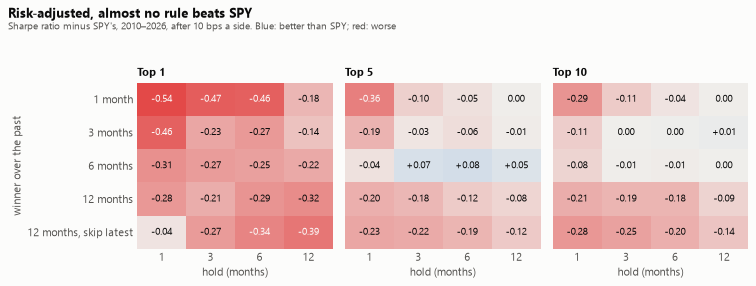

In [5]:
fig = plots.grid_heatmap(
    grid,
    "Risk-adjusted, almost no rule beats SPY",
    "Sharpe ratio minus SPY's, 2010–2026, after 10 bps a side. Blue: better than SPY; red: worse",
)
plots.save(fig, "baseline_grid_sharpe")

How many of the 60 rules beat SPY, by each dimension of the grid:

In [6]:
pd.concat({by: bt.grid_summary(grid, by) for by in ["top_n", "lookback", "hold"]})

cells  higher_return  higher_sharpe  median_cagr  median_sharpe  median_max_drawdown
top_n    1             20             15              0       0.1994         0.6053              -0.5638
         5             20             19              3       0.1983         0.7913              -0.3463
         10            20             19              3       0.1799         0.7810              -0.3114
lookback ret_12_1m     12             11              0       0.1758         0.6541              -0.3729
         ret_12m       12             12              0       0.1912         0.6852              -0.3929
         ret_1m        12              7              0       0.1688         0.7310              -0.3906
         ret_3m        12             11              2       0.2058         0.7980              -0.3249
         ret_6m        12             12              4       0.2282         0.8542              -0.2779
hold     1             15             11              0       0.1798         0.6481              -0.3850
         3             15             14              1       0.2018         0.6946              -0.3824
         6             15             14              2       0.1931         0.6958              -0.3635
         12            15             14              3       0.1995         0.7887              -0.3326

In [7]:
cells = grid.dropna(subset=["top_n"])
spy = grid.loc["spy"]
print(
    f"Higher return than SPY: {(cells['cagr'] > spy['cagr']).sum()} of {len(cells)}; "
    f"higher Sharpe: {(cells['sharpe'] > spy['sharpe']).sum()}; "
    f"deeper worst fall: {(cells['max_drawdown'] < spy['max_drawdown']).sum()}; "
    f"t > 2: {(cells['t_vs_spy'] > 2).sum()}; t > 3: {(cells['t_vs_spy'] > 3).sum()}"
)
cells.groupby("hold")["cost_per_year"].mean().rename("average cost per year").to_frame()

Higher return than SPY: 53 of 60; higher Sharpe: 6; deeper worst fall: 60; t > 2: 11; t > 3: 0


,average cost per year
hold,
1,0.0141
3,0.0063
6,0.0036
12,0.0020


## 4. Is the best rule luck? Chosen on 2010–2022, followed through the test years

The rule with the best Sharpe ratio on returns earned **2010–2022** is fixed, then scored on **2023 onwards**
(the test window, never used to choose), next to SPY and the equal-weight basket.

In [8]:
best, check, rank = bt.selection_check(rets, bench, rf, costs, config.RULE_CHECK_FROM)
print(
    f"Chosen: {plots.cell_label(**bt.parse_cell(best))} ({best}); "
    f"its Sharpe rank among the 60 in the test years: {rank}"
)
check

Chosen: Top 5 by 6-month return, held 6 months (pred_mom_6m_top5_h6); its Sharpe rank among the 60 in the test years: 4

cagr  volatility  sharpe  max_drawdown  beats_spy_months  months
       cell                                                                                  
before pred_mom_6m_top5_h6 0.2000      0.2278  0.8931       -0.2618            0.6065     155
       spy                 0.1245      0.1558  0.7941       -0.2331               NaN     155
       equal_weight        0.1366      0.1694  0.8081       -0.3013            0.5290     155
after  pred_mom_6m_top5_h6 0.5995      0.4264  1.2101       -0.2733            0.6087      46
       spy                 0.2092      0.1186  1.2877       -0.0780               NaN      46
       equal_weight        0.1424      0.1291  0.7476       -0.1143            0.4565      46

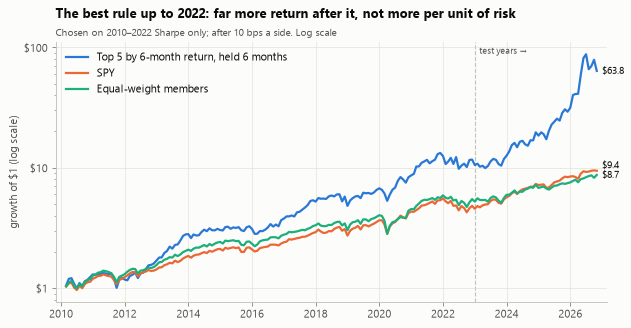

In [9]:
fig = plots.rule_growth_chart(
    rets[best],
    bench,
    plots.cell_label(**bt.parse_cell(best)),
    "The best rule up to 2022: far more return after it, not more per unit of risk",
    "Chosen on 2010–2022 Sharpe only; after 10 bps a side. Log scale",
    mark=config.RULE_CHECK_FROM,
    mark_label="test years →",
)
plots.save(fig, "baseline_best_rule")

Which stocks drove the rule in the test years: the members it picked most often.

In [10]:
best_pred = best.rsplit("_h", 1)[0]
late = panel[(panel[best_pred] == 1) & (panel["date"] >= config.RULE_CHECK_FROM)]
late["ticker"].value_counts().head(8).rename("month-ends picked").to_frame()

,month-ends picked
ticker,
NVDA,14
WDC,13
PLTR,13
STX,10
GEV,9
SNDK,9
MU,8
META,7


## 5. What this means for the next steps

- **On raw return the rule looks good; on risk it doesn't.** 53 of the 60 rules earn more than SPY, but
  only 6 have a better Sharpe ratio, and all 60 have a deeper worst fall. Buying winners mostly buys
  more risk.
- **Six-month winners, held longer, are the best corner.** The 6-month look-back is best on every
  measure. Last month's return is the worst (the short-term reversal seen in the feature analysis),
  and costs fall from about 1.4% a year with a 1-month hold to 0.2% with a 12-month hold.
- **A single stock is far too risky.** Top-1 rules have a median worst fall of −56%, against SPY's −23%.
- **The best rule on 2010–2022 earned far more in the test years, but not more per unit of risk.**
  It's the top 5 by 6-month return, held 6 months (Sharpe 0.89 vs SPY's 0.79 on 2010–2022). From 2023 it
  made 60% a year against SPY's 21%, ranking 4th of 60, but with 43% volatility against SPY's 12%, a
  worst fall of −27% against −8%, and a lower Sharpe (1.21 vs 1.29). The gain came from a handful of AI
  and memory-chip stocks: a bet on a market theme, not a steady edge.
- **The bar for the models:** beat SPY on a risk-adjusted basis at top 10. The best top-10 rule has a
  Sharpe ratio of 0.90 vs SPY's 0.88, close to a tie.

All of these are re-checked after the Alpha Vantage download finishes.